# comparing bc models with or without actions in the states

In [1]:
import os
import h5py
import pandas as pd
import numpy as np
import json
from scipy.stats import wilcoxon

In [2]:
import sys
sys.path.insert(0, "/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")

from src.data.data_processor_for_shards import ShardProcessor

In [3]:
models_dir = "/home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/"
with_actions_dir = "with_actions"
with_actions_path = os.path.join(models_dir, with_actions_dir)
without_actions_dir = "without_actions"
without_actions_path = os.path.join(models_dir, without_actions_dir)

if with_actions_dir not in os.listdir(models_dir):
    os.mkdir(with_actions_path)
if without_actions_dir not in os.listdir(models_dir):
    os.mkdir(without_actions_path)

random_search_folder_name = "choc_bc_transformer_action_standard_sepsis"

# create a list of all folders that begin with the random search folder name
random_search_folders = [f for f in os.listdir(models_dir) if f.startswith(random_search_folder_name)]

for folder in random_search_folders:
    # list the folders inside folder
    inner_folders = os.listdir(os.path.join(models_dir, folder))

    # load results.json from inner_folders[0]
    for inner_folder in inner_folders:
        if inner_folder == "config_manager.pkl":
            continue

        with open(os.path.join(models_dir, folder, inner_folder, "results.json"), "r") as f:
            results = json.load(f)
            actions_in_state = results['hyperparameters']['actions_in_state']
            print(f"Folder: {folder}, Actions in state: {actions_in_state}")

            if actions_in_state:
                # move folder to with_actions_dir
                os.rename(os.path.join(models_dir, folder), os.path.join(with_actions_path, folder))
            else:
                # move folder to without_actions_dir
                os.rename(os.path.join(models_dir, folder), os.path.join(without_actions_path, folder))
            break


Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_111423_558972_job2900873.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_180310_162446_job2901445.pbs-7, Actions in state: False
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_110617_518373_job2900870.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_181226_463101_job2901446.pbs-7, Actions in state: False
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_120037_288491_job2901444.pbs-7, Actions in state: False
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_111910_738544_job2901443.pbs-7, Actions in state: False
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_110656_314134_job2900872.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260601_110656_314047_job2900871.pbs-7, Actions in state: True


In [ ]:
directories = [with_actions_path, without_actions_path]
for directory in directories:
    inner_folder_list = []
    inner_inner_folder_list = []
    # val_mse_list = []
    val_loss_list = []
    
    # list the folders inside directory
    inner_folders = os.listdir(directory)

    for inner_folder in inner_folders:
        
        inner_inner_folders = os.listdir(os.path.join(directory, inner_folder))

        for inner_inner_folder in inner_inner_folders:
            if inner_inner_folder == "config_manager.pkl":
                continue

            with open(os.path.join(directory, inner_folder, inner_inner_folder, "results.json"), "r") as f:
                results = json.load(f)

                # val_mse = results['val_scores']['val/mse']
                val_loss = results['val_scores']['val/total_loss']

                inner_folder_list.append(inner_folder)
                inner_inner_folder_list.append(inner_inner_folder)
                # val_mse_list.append(val_mse)
                val_loss_list.append(val_loss)

    # find index of the best val_mse
    # best_index = np.argmin(val_mse_list)
    best_index = np.argmin(val_loss_list)
    best_inner_folder = inner_folder_list[best_index]
    best_inner_inner_folder = inner_inner_folder_list[best_index]
    # print(f"Best inner inner folder in {directory}: {best_inner_folder} {best_inner_inner_folder} with val_mse: {val_mse_list[best_index]}")
    print(f"Best inner inner folder in {directory}: {best_inner_folder} {best_inner_inner_folder} with val_loss: {val_loss_list[best_index]}")

    # create a final_model dir in directory if it doesn't exist, and move the best_inner_inner_folder to final_model
    final_model_dir = os.path.join(directory, "final_model")
    if not os.path.exists(final_model_dir):
        os.makedirs(final_model_dir)
    os.rename(os.path.join(directory, best_inner_folder, best_inner_inner_folder), os.path.join(final_model_dir, best_inner_inner_folder))


Best inner inner folder in /home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/without_actions: choc_bc_transformer_action_standard_sepsis_split_0_20260601_111910_738544_job2901443.pbs-7 unknown_cx3-20-2_20260601-115957_8a3e53d9 with val_loss: [3.636513582297734]


# manually move results into folders:
## equal_weighted_losses
## vaso_weighted_loss
## with_unweighted_binary_loss
## with_weighted_binary_loss

In [40]:
expt_folder = "with_weighted_binary_loss"
models_dir = os.path.join("/home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/", expt_folder)

In [41]:
import numpy as np
from scipy.stats import rankdata, wilcoxon

def paired_rank_biserial(x, y, lower_is_better=True):
    """
    Rank-biserial correlation for paired samples.
    Returns:
      r_rb: rank-biserial correlation in [-1, 1]
      n_eff: number of non-zero paired differences used
      n_zero: number of zero differences (ties dropped)
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # define direction: positive should mean x is better if lower_is_better
    d = (y - x) if lower_is_better else (x - y)

    # drop NaNs
    mask = np.isfinite(d)
    d = d[mask]

    # Wilcoxon/rank-biserial ignore zero differences
    d_nz = d[d != 0]
    n_zero = d.size - d_nz.size
    n_eff = d_nz.size

    if n_eff == 0:
        return np.nan, 0, n_zero

    ranks = rankdata(np.abs(d_nz), method="average")
    w_plus = ranks[d_nz > 0].sum()
    w_minus = ranks[d_nz < 0].sum()

    r_rb = (w_plus - w_minus) / (w_plus + w_minus)
    return r_rb, n_eff, n_zero

In [46]:
def compare_models(expt_folder):

    models_dir = os.path.join("/home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/", expt_folder)

    actions = ['intake', 'vis']
    with_actions_dir = os.path.join(models_dir, "with_actions", "final_model")
    without_actions_dir = os.path.join(models_dir, "without_actions", "final_model")

    # find the folder inside with_actions_dir and without_actions_dir
    with_actions_experiment_dir = os.path.join(with_actions_dir, os.listdir(with_actions_dir)[0])
    without_actions_experiment_dir = os.path.join(without_actions_dir, os.listdir(without_actions_dir)[0])

    predictions_file = "test_set_predictions.h5"

    # load the predictions from both models
    keys_to_load = ['stay_ids', 'index_ptr', 'predictions', 'targets', 'event']
    with_actions_predictions_path = os.path.join(with_actions_experiment_dir, predictions_file)
    with_actions_predictions =  ShardProcessor.load_dynamic_deephit_predictions_from_h5(
        with_actions_predictions_path, 
        keys_to_load=keys_to_load, 
        keys_to_exclude=None
    )

    without_actions_predictions_path = os.path.join(without_actions_experiment_dir, predictions_file)
    without_actions_predictions =  ShardProcessor.load_dynamic_deephit_predictions_from_h5(
        without_actions_predictions_path,
        keys_to_load=keys_to_load,
        keys_to_exclude=None
    )

    # calculate absolute error for each prediction, then perform Wilcoxon signed-rank test to compare the two models' predictions
    with_actions_absolute_error = np.abs(with_actions_predictions['predictions'] - with_actions_predictions['targets'])
    without_actions_absolute_error = np.abs(without_actions_predictions['predictions'] - without_actions_predictions['targets'])

    # calculate squared error for each prediction, then perform Wilcoxon signed-rank test to compare the two models' predictions
    with_actions_squared_error = (with_actions_predictions['predictions'] - with_actions_predictions['targets']) ** 2
    without_actions_squared_error = (without_actions_predictions['predictions'] - without_actions_predictions['targets']) ** 2

    # compare the two models using the Wilcoxon signed-rank test on each action in actions
    for i, action in enumerate(actions):
        abs_with = with_actions_absolute_error[:, i]
        abs_without = without_actions_absolute_error[:, i]
        # print the mean and median values for each model for this action
        print(f"Action: {action}, With actions - mean absolute error: {np.mean(abs_with)}, \
            median absolute error: {np.median(abs_with)}")
        print(f"Action: {action}, Without actions - mean absolute error: {np.mean(abs_without)}, \
            median absolute error: {np.median(abs_without)}")
        
        sq_with = with_actions_squared_error[:, i]
        sq_without = without_actions_squared_error[:, i]
        print(f"Mean squared error with actions: {np.mean(sq_with):.4f}, without actions: {np.mean(sq_without):.4f}")

        # Wilcoxon tests
        w_abs, p_abs = wilcoxon(abs_with, abs_without, zero_method="wilcox")
        w_sq, p_sq = wilcoxon(sq_with, sq_without, zero_method="wilcox")

        # Rank-biserial correlations
        r_abs, n_eff_abs, n_zero_abs = paired_rank_biserial(
            abs_with, abs_without, lower_is_better=True
        )
        r_sq, n_eff_sq, n_zero_sq = paired_rank_biserial(
            sq_with, sq_without, lower_is_better=True
        )

        print(f"\nAction: {action}")
        print(f"Absolute error: W={w_abs:.3f}, p={p_abs:.3g}, r_rb={r_abs:.3f}, n_eff={n_eff_abs}, zero_diffs={n_zero_abs}")
        print(f"Squared error : W={w_sq:.3f}, p={p_sq:.3g}, r_rb={r_sq:.3f}, n_eff={n_eff_sq}, zero_diffs={n_zero_sq}\n")
    
    return with_actions_predictions, without_actions_predictions

In [47]:
expt_folder = "with_weighted_binary_loss"
with_actions_predictions, without_actions_predictions = compare_models(expt_folder)

Action: intake, With actions - mean absolute error: 0.15145814418792725,             median absolute error: 0.057112276554107666
Action: intake, Without actions - mean absolute error: 0.14971694350242615,             median absolute error: 0.059544116258621216
Mean squared error with actions: 0.0623, without actions: 0.0592

Action: intake
Absolute error: W=4663195008.500, p=8.4e-12, r_rb=0.021, n_eff=138048, zero_diffs=57362
Squared error : W=4661302595.000, p=3.42e-12, r_rb=0.022, n_eff=138048, zero_diffs=57362

Action: vis, With actions - mean absolute error: 0.022321254014968872,             median absolute error: 0.0
Action: vis, Without actions - mean absolute error: 0.043059416115283966,             median absolute error: 0.0
Mean squared error with actions: 0.0051, without actions: 0.0094

Action: vis
Absolute error: W=194592384.500, p=0, r_rb=0.635, n_eff=46166, zero_diffs=149244
Squared error : W=207612266.000, p=0, r_rb=0.610, n_eff=46166, zero_diffs=149244



In [49]:
expt_folder = "vaso_weighted_loss"
with_actions_predictions_vaso_weighted, without_actions_predictions_vaso_weighted = compare_models(expt_folder)

Action: intake, With actions - mean absolute error: 0.12318132817745209,             median absolute error: 0.085410937666893
Action: intake, Without actions - mean absolute error: 0.13687452673912048,             median absolute error: 0.09688155353069305
Mean squared error with actions: 0.0285, without actions: 0.0341

Action: intake
Absolute error: W=8262129655.000, p=0, r_rb=0.135, n_eff=195410, zero_diffs=0
Squared error : W=8339423990.000, p=0, r_rb=0.126, n_eff=195410, zero_diffs=0

Action: vis, With actions - mean absolute error: 0.01970987394452095,             median absolute error: 0.0005531600909307599
Action: vis, Without actions - mean absolute error: 0.04113803058862686,             median absolute error: 0.005062764510512352
Mean squared error with actions: 0.0041, without actions: 0.0067

Action: vis
Absolute error: W=2203762596.500, p=0, r_rb=0.769, n_eff=195410, zero_diffs=0
Squared error : W=2331650335.500, p=0, r_rb=0.756, n_eff=195410, zero_diffs=0



In [50]:
actions = ['intake', 'vis']
def plot_ecdf(with_actions_predictions, without_actions_predictions, actions):
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd
    import numpy as np

    with_abs_error = np.abs(with_actions_predictions["predictions"] - with_actions_predictions["targets"])
    without_abs_error = np.abs(without_actions_predictions["predictions"] - without_actions_predictions["targets"])

    fig, axes = plt.subplots(1, len(actions), figsize=(6 * len(actions), 5), sharey=True)

    if len(actions) == 1:
        axes = [axes]

    for i, action in enumerate(actions):
        plot_df = pd.DataFrame({
            "Absolute Error": np.concatenate([
                with_abs_error[:, i],
                without_abs_error[:, i],
            ]),
            "Model": np.repeat(
                ["With Actions", "Without Actions"],
                [len(with_abs_error[:, i]), len(without_abs_error[:, i])]
            )
        })

        sns.ecdfplot(
            data=plot_df,
            x="Absolute Error",
            hue="Model",
            ax=axes[i],
            linewidth=2
        )

        axes[i].set_title(f"{action}: ECDF of absolute error")
        axes[i].set_xlabel("Absolute Error")
        axes[i].set_ylabel("Cumulative proportion")
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()

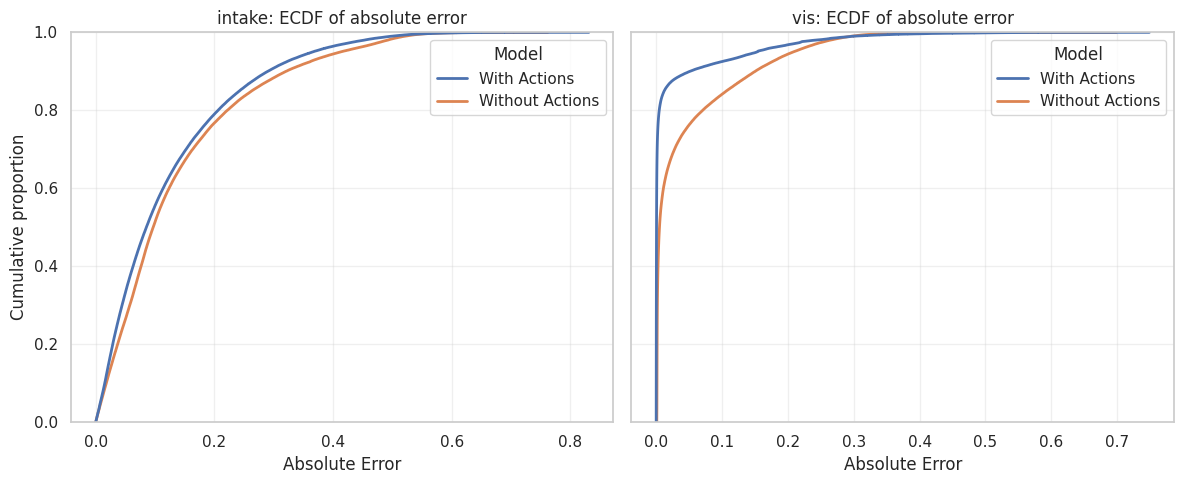

In [51]:
plot_ecdf(with_actions_predictions_vaso_weighted, without_actions_predictions_vaso_weighted, actions)

In [52]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_ecdf_by_target_split(with_actions_predictions, without_actions_predictions, actions):
    # sanity check: targets should match
    if not np.array_equal(with_actions_predictions["targets"], without_actions_predictions["targets"]):
        raise ValueError("Targets differ between with_actions and without_actions models.")

    with_preds = with_actions_predictions["predictions"]
    without_preds = without_actions_predictions["predictions"]
    targets_all = with_actions_predictions["targets"]

    fig, axes = plt.subplots(len(actions), 2, figsize=(12, 4 * len(actions)), sharey=True)

    if len(actions) == 1:
        axes = np.array([axes])  # make indexing consistent: axes[i, j]

    for i, action in enumerate(actions):
        targets = targets_all[:, i]
        with_abs_error = np.abs(with_preds[:, i] - targets)
        without_abs_error = np.abs(without_preds[:, i] - targets)

        for j, (mask, split_name) in enumerate([
            (targets == 0, "target == 0"),
            (targets > 0, "target > 0"),
        ]):
            with_subset = with_abs_error[mask]
            without_subset = without_abs_error[mask]

            ax = axes[i, j]

            if len(with_subset) + len(without_subset) == 0:
                ax.text(0.5, 0.5, f"No samples for {split_name}", ha="center", va="center", transform=ax.transAxes)
                ax.set_title(f"{action}: {split_name}")
                ax.set_xlabel("Absolute Error")
                ax.set_ylabel("Cumulative proportion")
                ax.grid(True, alpha=0.3)
                continue

            plot_df = pd.DataFrame({
                "Absolute Error": np.concatenate([with_subset, without_subset]),
                "Model": np.repeat(
                    ["With Actions", "Without Actions"],
                    [len(with_subset), len(without_subset)]
                )
            })

            sns.ecdfplot(
                data=plot_df,
                x="Absolute Error",
                hue="Model",
                ax=ax,
                linewidth=2
            )

            ax.set_title(f"{action}: ECDF ({split_name})")
            ax.set_xlabel("Absolute Error")
            ax.set_ylabel("Cumulative proportion")
            ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

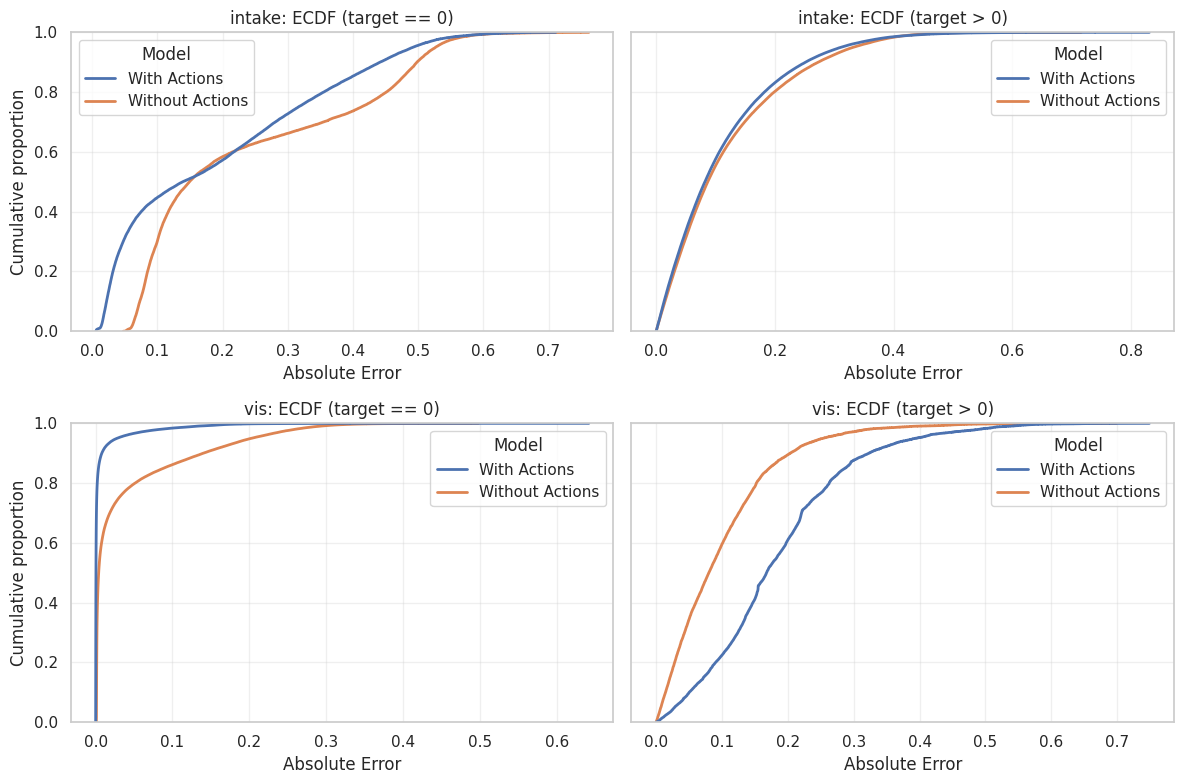

In [53]:
plot_ecdf_by_target_split(with_actions_predictions_vaso_weighted, without_actions_predictions_vaso_weighted, actions)